# 00-2　觀看前須知：讀懂 02 量子需要的波、複數與機率

**給誰看**：讀過 [00-1](01_before_newton.ipynb)、物理學到高中程度的人。
**目標**：讀完再去看 [02-1 波包](../02_quantum/01_wavepacket.ipynb)，每一段都看得懂。

寫法和 00-1 一樣：**白話 → 公式 → 跑程式親手看 → 02 哪裡會用到**。

量子力學難，主要是因為它同時用到三樣高中比較少碰的東西：**波**、**複數**、**機率**。
這本把三樣分開講清楚，最後再把它們組合成「波函數」。

| 章節 | 內容 | 02-1 對應的地方 |
|---|---|---|
| 0 | 符號對照表 | 全部 |
| 1 | 波：波長、波數、疊加 | `p0`、`k`、雙峰干涉 |
| 2 | 複數與 $e^{i\theta}$ | `1j`、`np.exp(1j * ...)`、Re $\psi$ |
| 3 | 機率分佈：平均和標準差 | $\langle x\rangle$、$\Delta x$、`stats` |
| 4 | 波函數：會算機率的複數波 | $\psi$、$\lvert\psi\rvert^2$、`gaussian` |
| 5 | 波包：很多波疊起來（不確定性原理的根源） | 實驗 2、3 |
| 6 | 波包為什麼會散開 | 實驗 1、`evolve_free` |
| 7 | $\hbar$ 有多小：為什麼日常看不到量子 | 實驗 5 |
| 8 | 機率守恆與可逆 | 實驗 4 |

## 0. 符號對照表

| 符號 | 念法 | 意思 |
|---|---|---|
| $\psi$ | psi（賽） | **波函數**，量子力學描述粒子的方式 |
| $\lvert\psi\rvert^2$ | psi 絕對值平方 | 在某個位置找到粒子的**機率密度** |
| $i$ | | 虛數單位，$i^2 = -1$。Python 寫成 `1j` |
| $e^{i\theta}$ | e 的 i theta 次方 | 一個在圓上轉的複數，第 2 章會講 |
| $h$ | 普朗克常數 | $6.63\times10^{-34}$ J·s，量子世界的尺度 |
| $\hbar$ | h bar | $h / 2\pi \approx 1.05\times10^{-34}$ J·s，物理學家更常用這個 |
| $\lambda$ | lambda | 波長 |
| $k$ | 波數 | $2\pi/\lambda$，每單位長度裡轉了幾個弧度 |
| $p$ | | 動量（質量 × 速度） |
| $\langle x\rangle$ | x 的平均 | 量很多次位置的平均值，也叫期望值 |
| $\Delta x$ | delta x | 位置的**標準差**，也就是「不確定度」，代表結果分散的程度 |
| $\sigma$ | sigma | 高斯分佈（鐘形曲線）的寬度 |
| $\partial$ | partial | 和 $d$ 一樣是「變化率」，用在函數同時依賴好幾個變數時（$x$ 和 $t$） |
| $m$ | | 質量 |

注意：00-1 的 $\Delta t$ 是「一小段時間」，到了量子力學，$\Delta x$、$\Delta p$ 指的是**標準差**，意思不一樣。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

## 1. 波：波長、波數、疊加

**白話**：波是一種**重複的起伏**，像水波、聲波、繩子上的波。最簡單的波是正弦波：

$$y = \cos(kx)$$

- **波長** $\lambda$：兩個波峰之間的距離
- **波數** $k = 2\pi/\lambda$：波長越短，$k$ 越大。物理學家喜歡用 $k$，因為公式比較乾淨

**疊加**：兩個波在同一個地方相遇，直接**相加**。波峰遇波峰變更高（**建設性干涉**），波峰遇波谷互相抵消（**破壞性干涉**）。

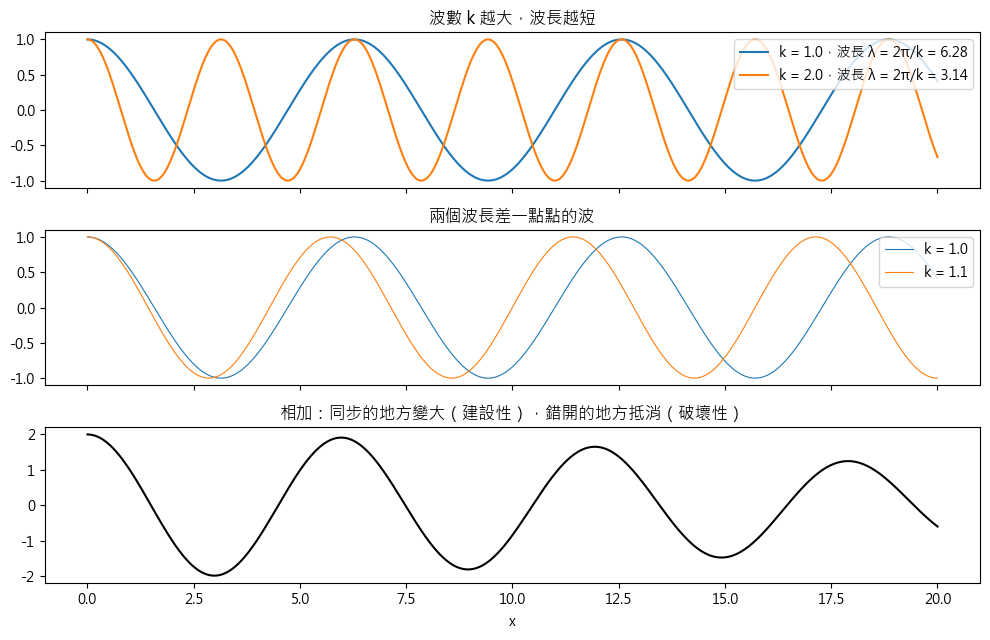

In [2]:
x = np.linspace(0, 20, 1000)
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)

for k, c in [(1.0, "C0"), (2.0, "C1")]:
    axes[0].plot(x, np.cos(k * x), c, label=f"k = {k}，波長 λ = 2π/k = {2 * np.pi / k:.2f}")
axes[0].set_title("波數 k 越大，波長越短")
axes[0].legend(loc="upper right")

w1, w2 = np.cos(1.0 * x), np.cos(1.1 * x)
axes[1].plot(x, w1, lw=0.8, label="k = 1.0")
axes[1].plot(x, w2, lw=0.8, label="k = 1.1")
axes[1].set_title("兩個波長差一點點的波")
axes[1].legend(loc="upper right")

axes[2].plot(x, w1 + w2, "k")
axes[2].set_title("相加：同步的地方變大（建設性），錯開的地方抵消（破壞性）")
axes[2].set_xlabel("x")
plt.tight_layout()
plt.show()

**觀察**：兩個波長只差一點點的波加在一起，會形成「一團一團」的形狀，這叫**拍頻**。
疊加的波越多，就越能拼出各種形狀。第 5 章會用很多個波拼出**只有一團**的「波包」。

**02 哪裡會用到**：02-1 的 $p_0$ 決定了波包裡波的波數；實驗 3 的貓態就是兩團波的疊加。

## 2. 複數與 $e^{i\theta}$

**白話**：$i$ 是一個「平方等於 −1」的數。聽起來很假，但它其實很具體：

> **複數就是平面上的一個點**：$z = a + bi$，$a$ 是橫座標（實部），$b$ 是縱座標（虛部）。

- **大小** $|z| = \sqrt{a^2 + b^2}$：離原點多遠（畢氏定理，和 00-1 的向量長度一樣）
- **大小的平方** $|z|^2 = a^2 + b^2$：**量子力學最常用的就是這個**

**最重要的公式（尤拉公式）**：

$$e^{i\theta} = \cos\theta + i\sin\theta$$

意思是：$e^{i\theta}$ 是**單位圓上、角度為 $\theta$ 的那個點**。$\theta$ 變大，它就沿著圓轉。
不管轉到哪裡，$|e^{i\theta}| = 1$，大小永遠是 1。

所以 $e^{i\theta}$ 可以理解成「**只有方向、沒有大小的旋轉**」。乘上 $e^{i\theta}$，就是把一個複數**轉 $\theta$ 角**，大小不變。

z = (3+4j) ，實部 3.0 ，虛部 4.0
|z| = 5.0 ，|z|² = 25.0
i² = (-1+0j)

e^(iθ)，θ = 60°：0.5000+0.8660j
cos θ + i sin θ ：0.5000+0.8660j（一樣，尤拉公式）
|e^(iθ)| = 1.0000（大小永遠是 1）


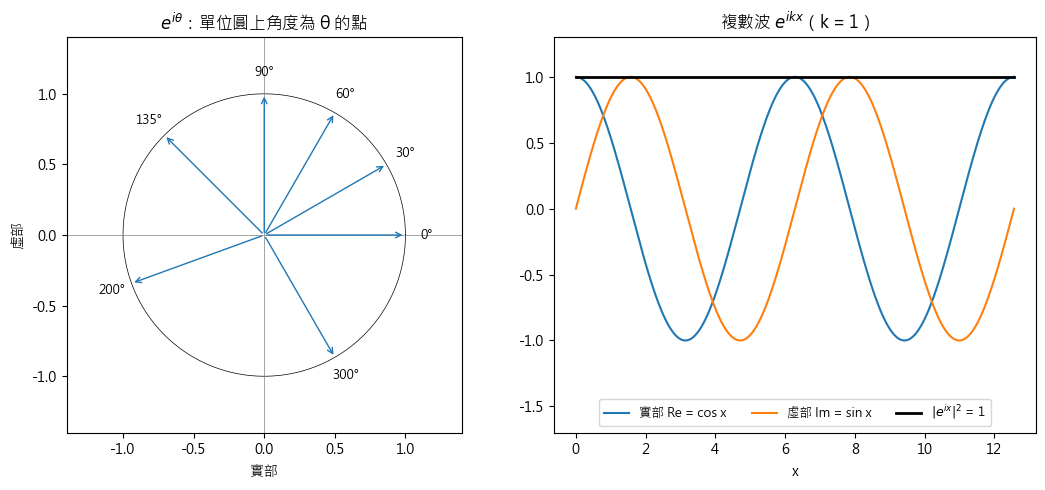

In [3]:
z = 3 + 4j                        # Python 的虛數單位寫成 j
print("z =", z, "，實部", z.real, "，虛部", z.imag)
print("|z| =", abs(z), "，|z|² =", abs(z) ** 2)
print("i² =", 1j * 1j)

theta = np.pi / 3                 # 60°
print(f"\ne^(iθ)，θ = 60°：{np.exp(1j * theta):.4f}")
print(f"cos θ + i sin θ ：{np.cos(theta) + 1j * np.sin(theta):.4f}（一樣，尤拉公式）")
print(f"|e^(iθ)| = {abs(np.exp(1j * theta)):.4f}（大小永遠是 1）")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
th = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(th), np.sin(th), "k", lw=0.5)
for t in np.radians([0, 30, 60, 90, 135, 200, 300]):
    p = np.exp(1j * t)
    ax.annotate("", xy=(p.real, p.imag), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0"))
    ax.text(1.15 * p.real, 1.15 * p.imag, f"{np.degrees(t):.0f}°", ha="center", va="center", fontsize=9)
ax.set_aspect("equal")
ax.set_xlim(-1.4, 1.4)
ax.set_ylim(-1.4, 1.4)
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("實部")
ax.set_ylabel("虛部")
ax.set_title(r"$e^{i\theta}$：單位圓上角度為 θ 的點")

ax = axes[1]
x = np.linspace(0, 4 * np.pi, 400)
wave = np.exp(1j * x)
ax.plot(x, wave.real, label=r"實部 Re = cos x")
ax.plot(x, wave.imag, label=r"虛部 Im = sin x")
ax.plot(x, np.abs(wave) ** 2, "k", lw=2, label=r"$|e^{ix}|^2$ = 1")
ax.set_xlabel("x")
ax.set_title(r"複數波 $e^{ikx}$（k = 1）")
ax.set_ylim(-1.7, 1.3)
ax.legend(loc="lower center", ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

**觀察**：複數波 $e^{ikx}$ 的實部是 cos 波、虛部是 sin 波，**但大小的平方處處都是 1**。
它的「起伏」全部藏在**相位**（角度）裡，這是量子力學很關鍵的一點：

> 波函數的相位決定了**干涉**和**運動**，但量粒子在哪裡時，只看得到 $|\psi|^2$。

**02 哪裡會用到**：`gaussian` 函式裡的 `np.exp(1j * p0 * x / hbar)` 就是這種複數波；動畫裡畫的 Re $\psi$ 是實部；`evolve_free` 裡乘上的 `np.exp(-1j * ...)` 就是「轉一個角度」。

## 3. 機率分佈：平均和標準差

**白話**：量子力學沒辦法告訴你「粒子**在**哪裡」，只能告訴你「在各個地方**找到它的機率**」。
所以要先熟悉描述一堆隨機結果的兩個數字：

- **平均** $\langle x\rangle$：結果的中心在哪裡
- **標準差** $\Delta x$：結果**分散**得多開。量子力學裡的「不確定度」指的就是它

**機率密度**：一條曲線，曲線下的**面積**代表機率。全部面積加起來一定是 **1**（100%），這叫**歸一化**。

最常見的形狀是**高斯分佈**（鐘形曲線），寬度參數 $\sigma$ 剛好就是標準差。

**親手看**：模擬「量 10000 次位置」，看結果的分佈：

平均 ⟨x⟩ = 2.009（設定 2.0）
標準差 Δx = 1.497（設定 σ = 1.5）
機率密度曲線下的面積 = 1.0000（歸一化：總機率 = 1）


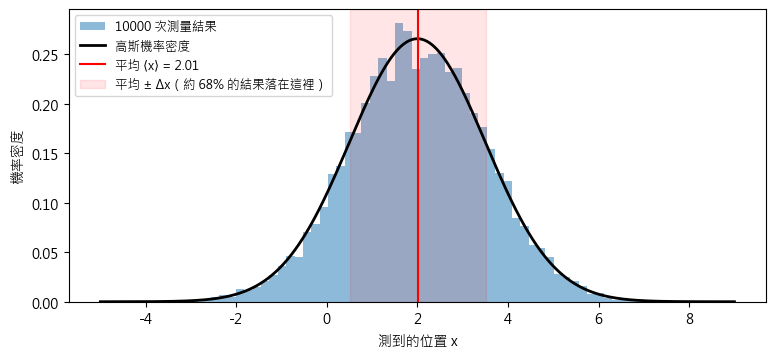

In [4]:
rng = np.random.default_rng(0)
mu, sigma = 2.0, 1.5
samples = rng.normal(mu, sigma, 10000)          # 假裝做了 10000 次位置測量

mean = samples.mean()
std = np.sqrt(np.mean((samples - mean) ** 2))   # 標準差：離平均多遠的「平方平均」再開根號
print(f"平均 ⟨x⟩ = {mean:.3f}（設定 {mu}）")
print(f"標準差 Δx = {std:.3f}（設定 σ = {sigma}）")

x = np.linspace(-5, 9, 500)
density = np.exp(-(x - mu) ** 2 / (2 * sigma**2)) / np.sqrt(2 * np.pi * sigma**2)
dx = x[1] - x[0]
print(f"機率密度曲線下的面積 = {np.sum(density) * dx:.4f}（歸一化：總機率 = 1）")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(samples, bins=60, density=True, alpha=0.5, label="10000 次測量結果")
ax.plot(x, density, "k", lw=2, label="高斯機率密度")
ax.axvline(mean, color="r", label=f"平均 ⟨x⟩ = {mean:.2f}")
ax.axvspan(mean - std, mean + std, color="r", alpha=0.1, label=f"平均 ± Δx（約 68% 的結果落在這裡）")
ax.set_xlabel("測到的位置 x")
ax.set_ylabel("機率密度")
ax.legend(loc="upper left", fontsize=9)
plt.show()

**怎麼從機率密度算平均和標準差？** 不用真的抽樣，直接用曲線算：

$$\langle x\rangle = \sum x \cdot (\text{密度}) \cdot dx, \qquad \Delta x = \sqrt{\sum (x - \langle x\rangle)^2 \cdot (\text{密度}) \cdot dx}$$

也就是「每個位置 × 它的機率，全部加起來」。

In [5]:
mean_from_curve = np.sum(x * density) * dx
std_from_curve = np.sqrt(np.sum((x - mean_from_curve) ** 2 * density) * dx)
print(f"從曲線算：⟨x⟩ = {mean_from_curve:.4f}，Δx = {std_from_curve:.4f}")

從曲線算：⟨x⟩ = 2.0000，Δx = 1.4999


**02 哪裡會用到**：02-1 的 `stats` 函式就是這兩行算法，只是把密度換成 $|\psi|^2$。
實驗 2 畫的 Δx 就是位置的標準差。

## 4. 波函數：會算機率的複數波

現在把前三章組合起來。量子力學說：

> 一個粒子由一個**複數波** $\psi(x)$ 描述。在 $x$ 附近找到它的**機率密度**是 $|\psi(x)|^2$。

這叫**玻恩詮釋**（1926 年）。所以：

- $\psi$ 本身是複數，**看不到**，它有大小也有相位
- $|\psi|^2$ 是實數、而且 ≥ 0，這是**看得到的**機率
- 總機率 = 1：$\sum |\psi|^2\,dx = 1$

**德布羅意關係**：波函數的**波數**對應粒子的**動量**：

$$p = \hbar k \qquad\left(\text{等同於 } p = \frac{h}{\lambda}\right)$$

波長越短，動量越大。所以 $e^{ip_0x/\hbar}$ 這個因子的意思就是「這個粒子帶有動量 $p_0$」。

02-1 的**高斯波包**，就是一個高斯形狀的大小，乘上一個帶動量的複數波：

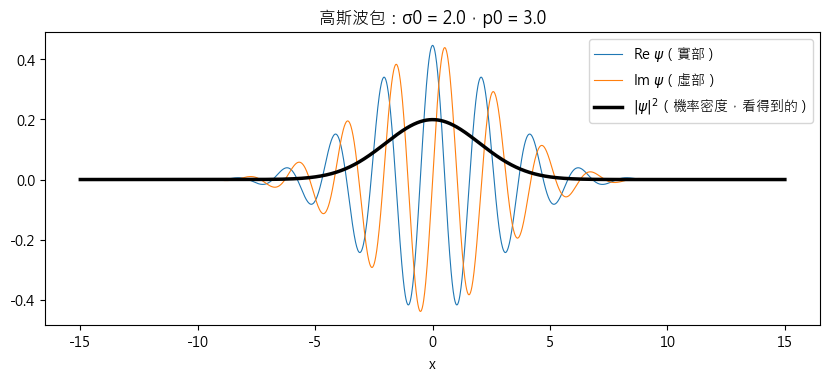

總機率 Σ|ψ|²dx = 1.000000
波長 λ = 2πħ/p0 = 2.094（圖中實部相鄰波峰的距離）


In [6]:
hbar = 1.0
x = np.linspace(-15, 15, 2000)
dx = x[1] - x[0]
sigma0, p0 = 2.0, 3.0

envelope = (2 * np.pi * sigma0**2) ** -0.25 * np.exp(-(x**2) / (4 * sigma0**2))   # 高斯形狀
carrier = np.exp(1j * p0 * x / hbar)                                              # 帶動量 p0 的複數波
psi = envelope * carrier

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(x, psi.real, lw=0.8, label=r"Re $\psi$（實部）")
ax.plot(x, psi.imag, lw=0.8, label=r"Im $\psi$（虛部）")
ax.plot(x, np.abs(psi) ** 2, "k", lw=2.5, label=r"$|\psi|^2$（機率密度，看得到的）")
ax.set_xlabel("x")
ax.set_title(f"高斯波包：σ0 = {sigma0}，p0 = {p0}")
ax.legend(loc="upper right")
plt.show()

print(f"總機率 Σ|ψ|²dx = {np.sum(np.abs(psi) ** 2) * dx:.6f}")
print(f"波長 λ = 2πħ/p0 = {2 * np.pi * hbar / p0:.3f}（圖中實部相鄰波峰的距離）")

**觀察**：實部和虛部在快速起伏，但 $|\psi|^2$ 是一個平滑的鐘形，**完全看不到裡面的波**。
那些起伏（相位）不是沒用：它們決定了粒子往哪裡跑、跑多快，以及會不會干涉。

**02 哪裡會用到**：這就是 02-1 的 `gaussian` 函式。注意 02-1 裡的 σ0 是**機率密度** $|\psi|^2$ 的標準差，所以公式裡寫 $4\sigma_0^2$ 而不是 $2\sigma_0^2$（平方之後才變成 $2\sigma_0^2$）。

## 5. 波包：很多波疊起來（不確定性原理的根源）

這一章是整本最重要的觀念。

第 1 章看到：一個純粹的正弦波**到處都一樣**，延伸到無限遠，完全沒有「位置」可言，但它的波數（動量）非常明確。

要做出一個**局限在某處**的粒子，就要把**很多不同波數**的波疊起來，讓它們只在一個地方建設性干涉，其他地方全部抵消。

**關鍵**：想要波包**越窄**（位置越確定），就需要**越多種波數**（動量越不確定）。這不是測量儀器不夠好，而是**波本身的數學性質**：

> 這就是**不確定性原理** $\Delta x\,\Delta p \ge \hbar/2$ 的由來。

**親手看**：把 200 個波數不同的波疊起來，改變波數的範圍：

波數範圍 Δk = 0.15  → 波包寬度 Δx = 3.338，乘積 Δx·Δk = 0.501


波數範圍 Δk = 0.6   → 波包寬度 Δx = 0.836，乘積 Δx·Δk = 0.502


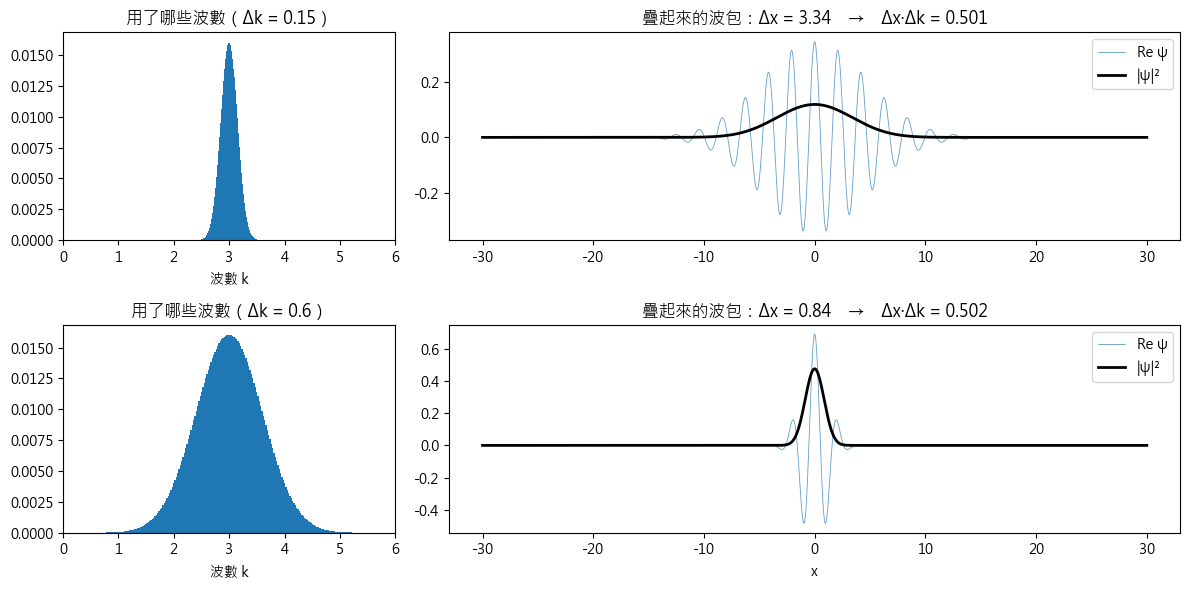

In [7]:
x = np.linspace(-30, 30, 3000)
dx = x[1] - x[0]
k0 = 3.0

fig, axes = plt.subplots(2, 2, figsize=(12, 6), gridspec_kw={"width_ratios": [1, 2.2]})
for row, dk in enumerate([0.15, 0.6]):
    ks = np.linspace(k0 - 4 * dk, k0 + 4 * dk, 200)
    weights = np.exp(-(ks - k0) ** 2 / (4 * dk**2))          # 波數的分佈（高斯形狀，寬度 dk）
    psi = sum(w * np.exp(1j * k * x) for w, k in zip(weights, ks))
    psi /= np.sqrt(np.sum(np.abs(psi) ** 2) * dx)            # 歸一化

    prob = np.abs(psi) ** 2
    mean_x = np.sum(x * prob) * dx
    Dx = np.sqrt(np.sum((x - mean_x) ** 2 * prob) * dx)

    axes[row, 0].bar(ks, weights**2 / np.sum(weights**2), width=ks[1] - ks[0])
    axes[row, 0].set_xlim(0, 6)
    axes[row, 0].set_title(f"用了哪些波數（Δk = {dk}）")
    axes[row, 0].set_xlabel("波數 k")
    axes[row, 1].plot(x, psi.real, lw=0.6, alpha=0.7, label="Re ψ")
    axes[row, 1].plot(x, prob, "k", lw=2, label="|ψ|²")
    axes[row, 1].set_title(f"疊起來的波包：Δx = {Dx:.2f}　→　Δx·Δk = {Dx * dk:.3f}")
    axes[row, 1].legend(loc="upper right")
    print(f"波數範圍 Δk = {dk:<5} → 波包寬度 Δx = {Dx:.3f}，乘積 Δx·Δk = {Dx * dk:.3f}")
axes[1, 1].set_xlabel("x")
plt.tight_layout()
plt.show()

**觀察**：

- 波數範圍**窄**（上圖），波包就**寬**；波數範圍**寬**（下圖），波包就**窄**。
- 不管怎麼調，**Δx·Δk 都是 0.5**。用的是高斯形狀時剛好是 0.5，其他形狀只會更大。
- 乘上 $\hbar$（因為 $p = \hbar k$），就得到 $\Delta x\,\Delta p = \hbar/2$，正是不確定性原理的下限。

**「把一個形狀拆成各種波數的成分」**這件事叫做**傅立葉轉換**，電腦用一個很快的演算法 **FFT** 來算。
反過來，「把各種波數的成分加回去」叫逆轉換（`ifft`）。

**02 哪裡會用到**：02-1 的 `np.fft.fft(psi)` 就是在問「這個波包由哪些波數組成」，用來算 Δp；實驗 2、3 驗證的 $\Delta x\Delta p \ge \hbar/2$，就是這一章的現象。

## 6. 波包為什麼會散開

**白話**：波包是很多波疊成的。如果每個波都用**一樣的速度**前進，波包會保持形狀，整團一起移動。
但物質波不是這樣。薛丁格方程式說，波數為 $k$ 的成分，相位轉動的速度是

$$\omega = \frac{\hbar k^2}{2m}$$

**和 $k^2$ 成正比**，所以波數大（動量大）的成分跑得比較快，波數小的跑得比較慢。
隨著時間過去，快的成分跑到前面、慢的落在後面，波包就**散開**了。這叫**色散**。

（02-1 的 `evolve_free` 就是做這件事：用 FFT 拆成各種波數，每個成分**轉一個和 $k^2$ 成正比的角度**，再加回去。）

**親手看**：比較「所有成分速度相同」（像真空中的光）和「速度 ∝ k」（物質波）：

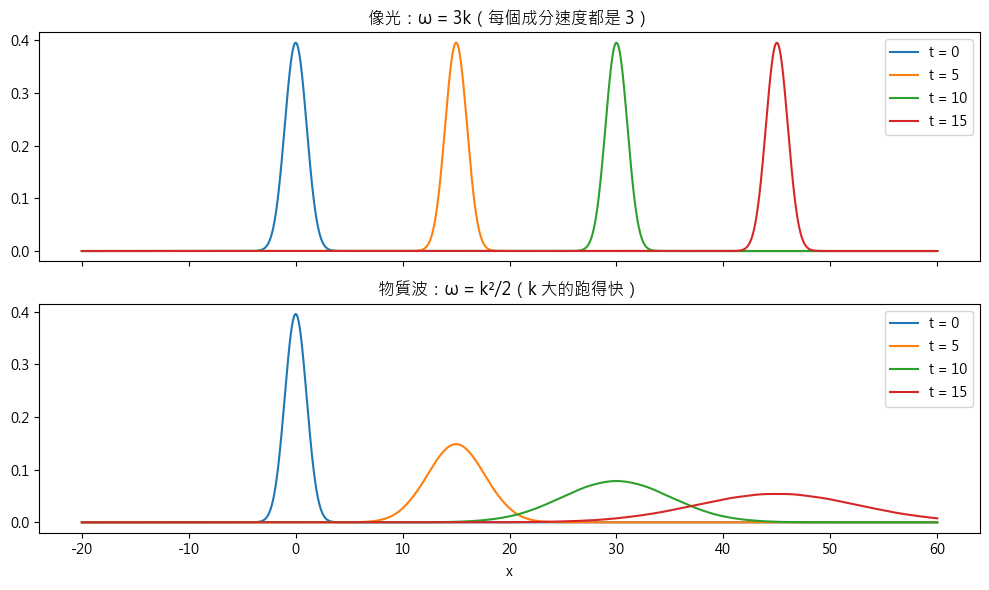

In [8]:
x = np.linspace(-20, 60, 4000)
dx = x[1] - x[0]
k0, dk = 3.0, 0.5
ks = np.linspace(k0 - 4 * dk, k0 + 4 * dk, 300)
weights = np.exp(-(ks - k0) ** 2 / (4 * dk**2))

def packet_at(t, omega):
    # 每個波數成分的相位各自轉 ω(k)·t，再加起來
    psi = sum(w * np.exp(1j * (k * x - omega(k) * t)) for w, k in zip(weights, ks))
    return np.abs(psi) ** 2 / (np.sum(np.abs(psi) ** 2) * dx)

cases = {
    "像光：ω = 3k（每個成分速度都是 3）": lambda k: 3.0 * k,
    "物質波：ω = k²/2（k 大的跑得快）": lambda k: k**2 / 2,
}
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (name, omega) in zip(axes, cases.items()):
    for t in [0, 5, 10, 15]:
        ax.plot(x, packet_at(t, omega), label=f"t = {t}")
    ax.set_title(name)
    ax.legend(loc="upper right")
axes[1].set_xlabel("x")
plt.tight_layout()
plt.show()

**觀察**：

- **上圖**：所有成分一樣快，波包**保持形狀**一起前進。
- **下圖**：物質波越跑越矮、越寬，也就是**散開了**。這就是 02-1 實驗 1 看到的現象。
- 兩張圖裡波包都以平均速度 3 前進（物質波中心的速度 = $\hbar k_0/m$ = 3，和牛頓的 $p/m$ 一樣）。

## 7. $\hbar$ 有多小：為什麼日常看不到量子

02-1 為了方便，把 $\hbar$ 和 $m$ 都設成 1，這叫**自然單位**：挑一套讓數字簡單的單位，物理不會變，就像 00-1 用 AU 和年讓 $GM = 4\pi^2$。

但現實中 $\hbar$ 非常小。用德布羅意波長 $\lambda = h/p$ 比較看看：

In [9]:
h = 6.626e-34      # J·s
objects = [
    ("電子（原子裡的速度）", 9.11e-31, 2.2e6),
    ("C60 富勒烯分子（實驗做過干涉）", 1.2e-24, 200),
    ("灰塵（1 微克）", 1e-9, 0.001),
    ("棒球（投手投球）", 0.145, 40),
]
print(f"{'物體':<26}{'質量 (kg)':>12}{'速度 (m/s)':>12}{'波長 λ = h/mv (m)':>22}")
for name, m, v in objects:
    print(f"{name:<26}{m:>12.2e}{v:>12.3g}{h / (m * v):>22.2e}")
print("\n比較：原子大小約 1e-10 m，原子核約 1e-15 m")

物體                             質量 (kg)    速度 (m/s)       波長 λ = h/mv (m)
電子（原子裡的速度）                    9.11e-31     2.2e+06              3.31e-10
C60 富勒烯分子（實驗做過干涉）             1.20e-24         200              2.76e-12
灰塵（1 微克）                      1.00e-09       0.001              6.63e-22
棒球（投手投球）                      1.45e-01          40              1.14e-34

比較：原子大小約 1e-10 m，原子核約 1e-15 m


**觀察**：

- **電子**的波長和原子差不多大，所以原子裡的電子完全是量子的。
- **C60 分子**（60 個碳原子的足球形分子）1999 年真的在實驗中做出了干涉條紋。
- **棒球**的波長約 $10^{-34}$ 公尺，比原子核還小 $10^{19}$ 倍，**完全不可能觀察到**。

所以「$\hbar \to 0$ 就回到牛頓力學」的實際意思是：**對大的東西來說，$\hbar$ 小到可以當成 0。**

**02 哪裡會用到**：實驗 5 把 $\hbar$ 調小，就是在模擬「越來越像棒球」的過程。

## 8. 機率守恆與可逆

**白話**：粒子不會憑空消失，所以不管過多久，**總機率永遠是 1**。

更深一層：量子力學的時間演化是**可逆**的。第 6 章的做法是讓每個成分轉一個角度，而「轉一個角度」永遠可以**轉回來**。
所以只要知道現在的波函數，就能完整推回過去的波函數，**資訊從來不會遺失**。這個性質叫**么正性**。

這和霍金的**黑洞資訊悖論**直接相關：黑洞蒸發後似乎只剩下雜亂的熱輻射，原本掉進去的資訊好像不見了，這會違反么正性。

**02 哪裡會用到**：實驗 4 檢查總機率一直是 1，並且「往前演化再往回演化」可以完美回到原狀。

## 準備好了：去讀 02-1

| 你在 02-1 看到 | 這本的哪裡 |
|---|---|
| $\psi$、$\lvert\psi\rvert^2$、機率密度 | 第 4 章 |
| `1j`、`np.exp(1j * ...)`、Re $\psi$ | 第 2 章 |
| $\langle x\rangle$、$\Delta x$、`stats` 函式 | 第 3 章 |
| `gaussian`、$\sigma_0$、$p_0$ | 第 4 章 |
| $p = \hbar k$、波數 `k` | 第 1、4 章 |
| `np.fft.fft`、動量空間 | 第 5 章 |
| $\Delta x\Delta p \ge \hbar/2$ | 第 5 章 |
| `evolve_free`、波包散開 | 第 6 章 |
| 薛丁格方程式裡的 $\partial$ | 第 0 章：只要知道它是「變化率」 |
| 貓態 | 第 1 章（疊加） |
| 總機率守恆、么正性 | 第 8 章 |
| $\hbar$ 調小、回到牛頓 | 第 7 章 |

02-1 開頭的**薛丁格方程式**不用會解，只要能讀懂它在說什麼：
「左邊是波函數隨時間的變化，右邊由它的彎曲程度決定」，結果就是第 6 章的「每個波數成分以 $\omega = \hbar k^2/2m$ 轉動相位」。

## 小練習

1. 第 2 章：算算看 $e^{i\pi}$ 等於多少？（這是著名的尤拉恆等式。）
2. 第 5 章：把 `dk` 改成 0.05 和 2.0，Δx·Δk 還是 0.5 嗎？
3. 第 7 章：如果把**你自己**（約 60 kg）以 1 m/s 走路，德布羅意波長是多少？